# The recommendation system (Chapter 3.4)

**Goal:** recommend recipes that (1) fit the user's diet preferences and (2) can be cooked from the ingredients
available at home, using the substitution network of Chapter 3.3 to rescue recipes with a missing ingredient.

| Research question | Where in this notebook |
|---|---|
| RQ1 structured data | 2 recipe table, 3 pantry vocabulary, 4 vegetarian rule |
| RQ2 pantry-based recommendation | 7 the algorithm (stage 2), 8 evaluation |
| RQ3 diet preferences | 7 the algorithm (stage 1), 8 funnel |
| RQ4 usefulness | 8 personas and simulation (exact matching as used by typical pantry apps vs. this system) |

**Files**
- `pantry_rules.py`: all *decisions* (pantry groups, staples, categories, vegetarian rule), commented.
- `recommender.py`: the *algorithm* (two-stage filtering, substitutions, ranking). The same code runs the Streamlit app.
- This notebook: prepares the data, documents every decision with numbers, evaluates the system and draws the figures.
- Outputs: `pantry_items.csv`, `meat_ingredients.csv` (decision tables, `;`-separated for Excel), the folder `app_data/`
  (input of the app), `persona_results.csv`, `simulation_results.csv`, and the figures `fig_recommender_*.png`.

**Reproducibility.** Every result is deterministic: the only random step (the simulation pantries) uses a fixed seed
(42); every sort has a complete tie-breaker (the recipe or ingredient id), so equal scores always come out in the same
order; and all manual decisions are stored in files the code reads (`merge_decisions.csv`, `pantry_rules.py`).
Re-running the notebook from the raw files with the library versions in `requirements.txt` gives byte-identical output
files (checked by running it twice and comparing the file hashes).

## 1. Load data

In [1]:
import re, sys, types, ast, os, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

pd.set_option("display.max_colwidth", 100)
OUT = Path("app_data"); OUT.mkdir(exist_ok=True)
CSV = dict(sep=";", encoding="utf-8-sig")          # ';' so that Hungarian Excel opens the files correctly

raw = pd.read_csv("RAW_recipes.csv")
pp = pd.read_csv("PP_recipes.csv", usecols=["id", "ingredient_ids"])
inter = pd.read_csv("RAW_interactions.csv", usecols=["recipe_id", "rating"])
try:
    ingr_map = pd.read_pickle("ingr_map.pkl")
except ModuleNotFoundError:                          # pickle written with an older pandas version
    shim = types.ModuleType("pandas.core.indexes.numeric")
    shim.Int64Index = shim.Float64Index = shim.UInt64Index = shim.NumericIndex = pd.Index
    sys.modules["pandas.core.indexes.numeric"] = shim
    ingr_map = pd.read_pickle("ingr_map.pkl")
edges = pd.read_csv("substitution_edges.csv")        # result of substitution_network.ipynb
decisions = pd.read_csv("merge_decisions.csv", **CSV).fillna("")
print(f"RAW recipes: {len(raw):,} | pre-processed recipes: {len(pp):,} | ratings: {len(inter):,} | "
      f"substitution edges: {len(edges):,}")

RAW recipes: 231,637 | pre-processed recipes: 178,265 | ratings: 1,132,367 | substitution edges: 2,340


## 2. The recipe table (data model)

### 2a. Why the recommender uses 178,265 recipes and not all 231,637

Pantry matching compares the user's ingredients with the recipe's ingredients. This only works with **canonical
ingredient identifiers** ("eggs", "large eggs" and "egg" must be the same thing). The dataset authors (Majumder et al., 2019)
provide these identifiers in `PP_recipes.csv`, but **only for a filtered subset of 178,265 recipes (77%)**.
The cell below shows what the filter was: the subset contains only recipes with 4–20 ingredients and a moderate
number of steps (the authors trained a text-generation model and removed very short and very long recipes).

**Decision:** the recommender uses this subset. The alternative (mapping the remaining 53,372 raw ingredient lists
ourselves) would give incomplete ingredient lists, which is worse for pantry matching than a smaller but clean catalogue.
The excluded recipes are mostly very simple (1–3 ingredients, e.g. drinks) or very complex (20+ ingredients).

In [2]:
raw["in_pp"] = raw["id"].isin(pp["id"])
cmp = raw.groupby("in_pp").agg(recipes=("id", "size"),
                               min_ingredients=("n_ingredients", "min"), max_ingredients=("n_ingredients", "max"),
                               median_ingredients=("n_ingredients", "median"),
                               min_steps=("n_steps", "min"), median_steps=("n_steps", "median"),
                               max_steps=("n_steps", "max"))
cmp.index = cmp.index.map({True: "in PP_recipes (used)", False: "not in PP_recipes"})
display(cmp)
outside = raw.loc[~raw["in_pp"]]
print(f"Excluded recipes with <4 or >20 ingredients: {(~outside['n_ingredients'].between(4, 20)).mean():.1%} "
      f"| with <3 or >20 steps: {(~outside['n_steps'].between(3, 20)).mean():.1%}")
print("Rest of the excluded recipes: removed by the authors' further (undocumented) filtering.")

,recipes,min_ingredients,max_ingredients,median_ingredients,min_steps,median_steps,max_steps
in_pp,,,,,,,
not in PP_recipes,53372,1,43,9.0,0,10.0,145
in PP_recipes (used),178265,4,20,9.0,3,8.0,37


Excluded recipes with <4 or >20 ingredients: 19.8% | with <3 or >20 steps: 36.9%
Rest of the excluded recipes: removed by the authors' further (undocumented) filtering.


### 2b. Ingredients, nutrition and ratings

- **Ingredients:** canonical ids from `PP_recipes.csv`, with the merge decisions of Chapter 3.3 applied
  (so that the recipe ingredients and the substitution network use exactly the same ids).
- **Nutrition (per serving, from `RAW_recipes.csv`):** calories, and protein converted from % daily value to grams:
  **protein (g) = PDV × 0.5**, because the reference daily value of protein is 50 g.
- **Data quality rule:** recipes with 0 kcal or more than 5,000 kcal per serving are implausible
  (typically a whole cake entered as one serving) and are removed.
- **Rating:** a 0 in the interactions means "review without stars" and is not a rating. The mean rating of a recipe
  with few reviews is unreliable (one 5★ review), so recipes are ranked by a **weighted (Bayesian) rating**:
  `(n × mean + m × C) / (n + m)` with C = mean of all ratings and m = 5. A recipe with few ratings is pulled towards
  the overall average; with many ratings its own mean dominates.

In [3]:
STEM_FIX = {"flmy": "flour", "pastum": "pasta", "stevium": "stevia", "olife": "olive", "molass": "molasses",
            "asparagu": "asparagus", "spaghettus": "spaghetti", "chily": "chili", "hummu": "hummus",
            "couscou": "couscous", "truvium": "truvia"}
canonical = ingr_map.drop_duplicates("id").set_index("id")["replaced"]
display_name = canonical.apply(lambda s: " ".join(STEM_FIX.get(w, w) for w in s.split()))

# merge decisions of Chapter 3.3 (same code as in substitution_network.ipynb)
name_to_id = {}
for i, n in display_name.items():
    name_to_id.setdefault(n, int(i))
merges = decisions[decisions["decision"].str.strip().str.lower() == "merge"]
MERGE_ID = {name_to_id[s]: name_to_id[d] for s, d in zip(merges["ingredient"], merges["merge_into"])
            if s in name_to_id and d in name_to_id and s != d}
for k in list(MERGE_ID):
    while MERGE_ID[k] in MERGE_ID:
        MERGE_ID[k] = MERGE_ID[MERGE_ID[k]]

pp["ingredient_ids"] = pp["ingredient_ids"].apply(
    lambda s: sorted({MERGE_ID.get(int(x), int(x)) for x in re.findall(r"\d+", s)}))

rec = raw.merge(pp, on="id")
nut = np.array(rec["nutrition"].apply(ast.literal_eval).tolist())
rec["calories"] = nut[:, 0]
rec["fat_pdv"], rec["sugar_pdv"], rec["sodium_pdv"] = nut[:, 1], nut[:, 2], nut[:, 3]
rec["protein_pdv"], rec["sat_fat_pdv"], rec["carbs_pdv"] = nut[:, 4], nut[:, 5], nut[:, 6]
rec["protein_g"] = rec["protein_pdv"] * 0.5

before = len(rec)
rec = rec[(rec["calories"] > 0) & (rec["calories"] <= 5000)].copy()
print(f"Implausible calorie values removed: {before - len(rec):,} recipes ({(before - len(rec)) / before:.2%})")

rated = inter[inter["rating"] > 0]
C, M = rated["rating"].mean(), 5
stats = rated.groupby("recipe_id")["rating"].agg(n_ratings="size", mean_rating="mean")
rec = rec.join(stats, on="id")
rec["n_ratings"] = rec["n_ratings"].fillna(0).astype(int)
rec["weighted_rating"] = ((rec["n_ratings"] * rec["mean_rating"].fillna(C) + M * C) / (rec["n_ratings"] + M)).round(3)
rec["name"] = rec["name"].fillna("").str.split().str.join(" ").str.capitalize()
rec["tags"] = rec["tags"].apply(ast.literal_eval)
rec["vegetarian_tag"] = rec["tags"].apply(lambda t: "vegetarian" in t or "vegan" in t)

print(f"Recipe catalogue: {len(rec):,} recipes | overall mean rating C = {C:.2f} | "
      f"recipes without any star rating: {(rec['n_ratings'] == 0).mean():.1%}")
display(rec[["calories", "protein_g", "n_ratings", "mean_rating", "weighted_rating"]].describe().round(1))

Implausible calorie values removed: 726 recipes (0.41%)


Recipe catalogue: 177,539 recipes | overall mean rating C = 4.66 | recipes without any star rating: 1.1%


,calories,protein_g,n_ratings,mean_rating,weighted_rating
count,177539.0,177539.0,177539.0,175578.0,177539.0
mean,429.7,16.7,5.0,4.6,4.6
std,488.9,19.7,17.6,0.6,0.2
min,0.1,0.0,0.0,1.0,2.8
25%,176.9,3.5,1.0,4.3,4.6
50%,309.4,9.5,2.0,4.8,4.7
75%,501.6,25.5,4.0,5.0,4.8
max,4993.6,690.0,1496.0,5.0,5.0


## 3. Pantry vocabulary: pantry items and categories

**Problem:** the canonical vocabulary is too fine for a pantry screen. *chicken*, *chicken breast*, *chicken thigh* and
*cooked chicken* are separate ingredients; so are *lemon*, *lemon juice* and *lemon zest*. A user who ticks "chicken"
should match all chicken recipes.

**Solution: a two-level vocabulary** (rules in `pantry_rules.py`):
1. **Pantry item**: what the user ticks. Groups of canonical ingredients were defined by hand (`GROUPS`, e.g.
   "lemon" = lemon, lemon juice, lemon zest, lemon rind ...). Every other ingredient that occurs in **at least 300 recipes**
   becomes its own pantry item. Threshold: these items cover ~88% of all ingredient mentions while the list stays short
   enough for a selection screen.
2. **Category**: shop-style groups (Vegetables, Meat & fish, Eggs & dairy ...) to organise the screen. Assigned by
   keyword rules plus manual overrides. The swap families of the network (Chapter 3.3) were the starting point, but
   they are not used directly: they only contain ingredients that users swap, and some of them are not
   meaningful as a shopping category (e.g. "Aromatics & salt").
3. **Staples** (salt, black pepper, water, vegetable oil) are assumed to be available, following the frequency analysis
   of Chapter 3.2 (salt alone appears in 37% of the recipes). They can be switched off in the app.

The result is written to **`pantry_items.csv`**: one row per canonical ingredient with its pantry item, category and the
source of the decision. As with `merge_decisions.csv`, an existing file is **not overwritten**, so manual corrections in
Excel are kept (delete the file to regenerate it from the rules).

In [4]:
import pantry_rules as R
importlib.reload(R)

PANTRY_FILE = "pantry_items.csv"
MIN_RECIPES = 300
freq = rec["ingredient_ids"].explode().astype(int).value_counts()
used_name = {int(i): display_name.get(i, str(i)) for i in freq.index}

def category_of(item):
    if item in R.CATEGORY_OVERRIDE:
        return R.CATEGORY_OVERRIDE[item]
    for cat, rx in R.CATEGORY_RULES:
        if re.search(rx, item):
            return cat

def build_pantry_table():
    item_of_name = {n: item for item, names in R.GROUPS.items() for n in names}
    rows = []
    for i, n in used_name.items():
        if n in item_of_name:
            rows.append((i, n, item_of_name[n], "manual group"))
        elif freq[i] >= MIN_RECIPES:
            rows.append((i, n, n, f"own item (>= {MIN_RECIPES} recipes)"))
    t = pd.DataFrame(rows, columns=["ingredient_id", "ingredient", "pantry_item", "source"])
    t["recipes"] = t["ingredient_id"].map(freq).astype(int)
    t["category"] = t["pantry_item"].map(category_of)
    t["staple"] = t["pantry_item"].isin(R.STAPLE_ITEMS)
    return t.sort_values(["category", "pantry_item", "recipes", "ingredient_id"],
                         ascending=[True, True, False, True], kind="mergesort")[
        ["category", "pantry_item", "staple", "ingredient", "ingredient_id", "recipes", "source"]]

if not os.path.exists(PANTRY_FILE):
    build_pantry_table().to_csv(PANTRY_FILE, index=False, **CSV)
    print(f"Created {PANTRY_FILE} from the rules.")
else:
    print(f"Using the existing {PANTRY_FILE} (manual edits are kept; delete it to regenerate).")
pantry = pd.read_csv(PANTRY_FILE, **CSV)

print(f"Pantry items: {pantry['pantry_item'].nunique()} | canonical ingredients covered: {len(pantry)} | "
      f"share of all ingredient mentions covered: {freq[pantry['ingredient_id']].sum() / freq.sum():.1%}")
per_cat = (pantry.groupby("category").agg(pantry_items=("pantry_item", "nunique"), ingredients=("ingredient", "size"))
           .sort_values("pantry_items", ascending=False))
display(per_cat)
print("Example groups:")
display(pantry[pantry["pantry_item"].isin(["chicken", "lemon", "pasta"])][["pantry_item", "ingredient", "recipes"]])

Using the existing pantry_items.csv (manual edits are kept; delete it to regenerate).
Pantry items: 307 | canonical ingredients covered: 736 | share of all ingredient mentions covered: 87.8%


,pantry_items,ingredients
category,,
Herbs & spices,53,107
Vegetables,40,115
Eggs & dairy,33,57
Sauces & condiments,28,45
Fruits,25,61
Baking,22,44
"Grains, pasta & bread",20,71
Meat & fish,18,73
Drinks & alcohol,17,20


Example groups:


,pantry_item,ingredient,recipes
174,lemon,lemon juice,15184
175,lemon,lemon,2983
176,lemon,"lemon, juice of",1571
177,lemon,lemon zest,1513
178,lemon,lemon rind,849
179,lemon,"lemon, zest of",694
180,lemon,lemon peel,613
181,lemon,lemon wedge,536
182,lemon,"lemon, rind of",336
183,lemon,"lemons, juice of",307


## 4. The vegetarian rule

Food.com has a `vegetarian` tag, but tags are set by the recipe authors and are incomplete: many meat-free recipes
(desserts, salads) are not tagged. **Decision:** a recipe is vegetarian if **none of its ingredients is meat, fish or
seafood** (or gelatin, lard, suet). The meat ingredients are found with a keyword rule (`MEAT_RX` in `pantry_rules.py`)
plus a list of exceptions (`NOT_MEAT_RX`: "hamburger bun", "oyster mushroom", "steak sauce" ...). The full list is written to
`meat_ingredients.csv` for checking. The rule is applied to the canonical names **and** to the original
ingredient text, because the canonical mapping sometimes drops the meat word ("beef rump" -> "rum").
The tag is used to **validate** the rule.

In [5]:
all_ids = sorted(set(freq.index.astype(int)))
names = pd.DataFrame({"ingredient_id": all_ids, "name": [used_name[i] for i in all_ids]})
names["meat"] = names["name"].str.contains(R.MEAT_RX, regex=True) & ~names["name"].str.contains(R.NOT_MEAT_RX, regex=True)
names["recipes"] = names["ingredient_id"].map(freq).astype(int)
names[names["meat"]].sort_values(["recipes", "ingredient_id"], ascending=[False, True], kind="mergesort")[["name", "ingredient_id", "recipes"]] \
    .to_csv("meat_ingredients.csv", index=False, **CSV)

meat_ids = set(names.loc[names["meat"], "ingredient_id"])
meat_in_ids = rec["ingredient_ids"].apply(lambda ids: any(i in meat_ids for i in ids))

# The same rule on the original ingredient text: the canonical mapping sometimes drops the meat word
# ("beef rump" -> "rum", "tuna in olive oil" -> "olive oil"), so checking only the canonical names is not enough.
MEAT, NOT_MEAT = re.compile(R.MEAT_RX), re.compile(R.NOT_MEAT_RX)
def text_has_meat(ings):
    ings = ast.literal_eval(ings) if isinstance(ings, str) else ings
    return any(MEAT.search(i) and not NOT_MEAT.search(i) for i in ings)
meat_in_text = rec["ingredients"].apply(text_has_meat)
rec["vegetarian"] = ~meat_in_ids & ~meat_in_text
only_text = rec[meat_in_text & ~meat_in_ids]
print(f"Found only in the original text (canonical mapping lost the meat word): {len(only_text):,} recipes, e.g. "
      + "; ".join(only_text["ingredients"].head(400).apply(
          lambda x: next(i for i in (ast.literal_eval(x) if isinstance(x, str) else x)
                         if MEAT.search(i) and not NOT_MEAT.search(i))).drop_duplicates().head(6)))
print(f"Meat / fish ingredients: {len(meat_ids):,}  (top: "
      f"{', '.join(names[names['meat']].nlargest(8, 'recipes')['name'])})")
print(f"Vegetarian by ingredient rule: {rec['vegetarian'].mean():.1%} | vegetarian/vegan tag: {rec['vegetarian_tag'].mean():.1%}")
display(pd.crosstab(rec["vegetarian_tag"].map({True: "tagged vegetarian", False: "not tagged"}),
                    rec["vegetarian"].map({True: "no meat ingredient", False: "contains meat"}), margins=True))
bad = rec[rec["vegetarian_tag"] & ~rec["vegetarian"]]
print(f"Tagged vegetarian but containing a meat ingredient: {len(bad):,} "
      f"({len(bad) / rec['vegetarian_tag'].sum():.1%} of the tagged recipes) -> the tag alone would let these through. Examples:")
display(bad.head(8).assign(meat=lambda d: d["ingredient_ids"].apply(
    lambda ids: ", ".join(used_name[i] for i in ids if i in meat_ids)))[["name", "meat"]])

C:\Users\soosa\AppData\Local\Temp\ipykernel_50552\1365956717.py:3: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  names["meat"] = names["name"].str.contains(R.MEAT_RX, regex=True) & ~names["name"].str.contains(R.NOT_MEAT_RX, regex=True)


Found only in the original text (canonical mapping lost the meat word): 209 recipes, e.g. berry gelatin; chili with chicken and beans; beef stew; orange-pineapple flavored gelatin; underblade steak; whale meat
Meat / fish ingredients: 1,013  (top: chicken broth, chicken breast, bacon, ground beef, sausage, chicken stock, lean ground beef, chicken breast half)
Vegetarian by ingredient rule: 57.1% | vegetarian/vegan tag: 15.4%


vegetarian,contains meat,no meat ingredient,All
vegetarian_tag,,,
not tagged,75588,74589,150177
tagged vegetarian,649,26713,27362
All,76237,101302,177539


Tagged vegetarian but containing a meat ingredient: 649 (2.4% of the tagged recipes) -> the tag alone would let these through. Examples:


,name,meat
264,Boo tiful jell o cups,orange gelatin
328,I don t believe it s lemon tofu cheesecake,liver
510,Not meatballs,ground meat substitute
915,3 cheese spinach roasted red pepper calzones,prosciutto
944,3 onion mushroom and garlic soup,beef base
1453,A la rousse salad romanian,sausage
1545,A vegetarian finnish mashed potato casserole,chicken broth
1806,Acorn squash and granny smith apple soup,chicken broth


### 4b. Manual check of the extra vegetarian recipes

The rule finds far more vegetarian recipes than the tag (57.2% vs 15.4%). To check that the extra ones are really
vegetarian, **30 random recipes that the rule calls vegetarian but that have no vegetarian tag** are written to
`vegetarian_check_sample.csv` (fixed seed 42). Fill in the column `is_vegetarian` with `y` or `n` in Excel (add a short
`note` for every `n`). As with the other decision files, an existing file is **not overwritten**, so the marks are kept;
the summary below counts them.

In [6]:
VEG_CHECK_FILE = "vegetarian_check_sample.csv"
extra = rec[rec["vegetarian"] & ~rec["vegetarian_tag"]]
print(f"Vegetarian by the rule but not tagged: {len(extra):,} recipes")
if not os.path.exists(VEG_CHECK_FILE):
    sample = extra.sample(30, random_state=42).sort_values("id")
    pd.DataFrame({"id": sample["id"], "name": sample["name"],
                  "ingredients": sample["ingredients"].apply(lambda x: ", ".join(ast.literal_eval(x) if isinstance(x, str) else x)),
                  "is_vegetarian": "", "note": ""}).to_csv(VEG_CHECK_FILE, index=False, **CSV)
    print(f"Created {VEG_CHECK_FILE} (30 recipes) - mark is_vegetarian with y / n.")
else:
    print(f"Using the existing {VEG_CHECK_FILE} (marks are kept; delete it to draw the sample again).")
check = pd.read_csv(VEG_CHECK_FILE, **CSV, keep_default_na=False)
marked = check["is_vegetarian"].str.strip().str.lower()
n_y, n_n = int((marked == "y").sum()), int((marked == "n").sum())
if n_y + n_n:
    print(f"Marked: {n_y + n_n} of {len(check)} | vegetarian: {n_y} ({n_y / (n_y + n_n):.0%}) | not vegetarian: {n_n}")
    display(check[marked == "n"][["name", "note"]])
else:
    print("Not marked yet.")

Vegetarian by the rule but not tagged: 74,589 recipes
Created vegetarian_check_sample.csv (30 recipes) - mark is_vegetarian with y / n.
Not marked yet.


## 5. Substitutions from the network

The edges of `substitution_edges.csv` (Chapter 3.3, at least 5 reviews each) are used. The network keeps *light* versions
as separate nodes (e.g. "sour cream (light)"), but recipes and pantry items do not distinguish light versions, so here
the light suffix is removed and the evidence is added together. Edges that become a self-swap
(sour cream → light sour cream) are dropped.

**Only strong swaps are used for pantry matching.** A first version used all edges, and the result was not credible:
almost every missing ingredient had *some* substitute; for the vegetarian persona, 881 of 995 "cookable" recipes
(89%) were only cookable through a swap (first row of the table below). The cause is the long tail of rare alternatives (e.g. 1–2% of the cooks who replaced
an ingredient used something unusual). **Decision:** a swap is used only if
- at least **10 reviews** mention it (stricter than the 5 used to draw the network), and
- it accounts for at least **5% of all substitutions of that ingredient** (share = p(b|a), Chapter 3.3).

In addition, a recipe may contain at most **2 swaps** (`MAX_SWAPS` in `recommender.py`): with more changes it is no
longer the same dish. The thresholds were chosen by comparing several settings on the persona pantries of Section 8
(see the table below): stricter settings change the results only slightly, while looser ones inflate them.

In [7]:
e = edges.copy()
e["a_id"] = e["a_node"].astype(str).str.replace("_light", "", regex=False).astype(int)
e["b_id"] = e["b_node"].astype(str).str.replace("_light", "", regex=False).astype(int)
e = e[e["a_id"] != e["b_id"]]
e["rating_x_support"] = e["mean_rating"] * e["support"]
subs = e.groupby(["a_id", "b_id"], as_index=False).agg(support=("support", "sum"), rx=("rating_x_support", "sum"))
subs["mean_rating"] = (subs["rx"] / subs["support"]).round(2)
subs["a"] = subs["a_id"].map(display_name)
subs["b"] = subs["b_id"].map(display_name)
subs["share"] = (subs["support"] / subs.groupby("a_id")["support"].transform("sum")).round(3)
subs = subs.drop(columns="rx").sort_values(["support", "a_id", "b_id"], ascending=[False, True, True], kind="mergesort")

MIN_SUPPORT_REC, MIN_SHARE = 10, 0.05
strong = subs[(subs["support"] >= MIN_SUPPORT_REC) & (subs["share"] >= MIN_SHARE)]
print(f"Network edges: {len(edges):,} -> without light duplicates: {len(subs):,} -> strong swaps used: {len(strong):,} "
      f"| ingredients with at least one strong substitute: {strong['a_id'].nunique()}")
display(strong.head(8))

Network edges: 2,340 -> without light duplicates: 2,300 -> strong swaps used: 758 | ingredients with at least one strong substitute: 319


,a_id,b_id,support,mean_rating,a,b,share
1954,6906,208,1898,4.79,sugar,artificial sweetener,0.599
303,840,5006,859,4.74,butter,olive oil,0.299
1213,4574,840,658,4.77,margarine,butter,0.771
2144,7557,170,549,4.70,vegetable oil,applesauce,0.289
1064,3668,4717,521,4.72,heavy cream,milk,0.381
978,3484,3548,461,4.70,ground beef,ground turkey,0.389
2203,7642,5298,459,4.81,walnut,pecan,0.673
1966,6906,3723,455,4.76,sugar,honey,0.144


In [8]:
# Sensitivity check of the thresholds (documentation of the decision above)
import recommender
importlib.reload(recommender)
for col in ["ingredients", "steps"]:
    rec[col] = rec[col].apply(ast.literal_eval)
keep = ["id", "name", "minutes", "n_steps", "description", "ingredients", "steps", "ingredient_ids",
        "calories", "protein_g", "fat_pdv", "sat_fat_pdv", "sugar_pdv", "sodium_pdv", "carbs_pdv",
        "vegetarian", "vegetarian_tag", "n_ratings", "mean_rating", "weighted_rating"]
rec[keep].to_parquet(OUT / "recipes.parquet", index=False)
pantry.to_csv(OUT / "pantry_items.csv", index=False, **CSV)
extra = set(subs["a_id"]) | set(subs["b_id"])
names_all = pd.concat([names, pd.DataFrame({"ingredient_id": sorted(extra - set(names["ingredient_id"]))})])
names_all["ingredient_id"] = names_all["ingredient_id"].astype(int)
names_all["name"] = names_all["ingredient_id"].map(display_name).fillna(names_all["name"])
names_all["meat"] = names_all["name"].str.contains(R.MEAT_RX, regex=True) & ~names_all["name"].str.contains(R.NOT_MEAT_RX, regex=True)
names_all[["ingredient_id", "name", "meat"]].to_csv(OUT / "ingredient_names.csv", index=False, **CSV)

test_pantries = {
    "student": ["egg", "milk", "butter", "flour", "sugar", "onion", "garlic", "tomato", "pasta", "rice", "cheddar", "potato"],
    "vegetarian": ["onion", "garlic", "tomato", "bell pepper", "spinach", "chickpea", "beans", "rice", "pasta", "feta",
                   "yogurt", "lemon", "olive oil", "mushroom", "carrot", "egg", "cumin"],
}
settings = [("all edges, unlimited swaps", 5, 0, 99), ("all edges, max 2 swaps", 5, 0, 2),
            ("support>=10, share>=5%, max 2 swaps (chosen)", 10, 0.05, 2),
            ("support>=20, share>=10%, max 2 swaps", 20, 0.10, 2)]
rows = []
for label, sup, sh, mx in settings:
    subs[(subs["support"] >= sup) & (subs["share"] >= sh)].to_csv(OUT / "substitutions.csv", index=False, **CSV)
    rs_t = recommender.Recommender()
    row = {"setting": label}
    for p, items_p in test_pantries.items():
        c = rs_t.cookable(items_p, max_swaps=mx)
        row[f"{p}: exact"] = int(c["exact"].sum())
        row[f"{p}: with swaps"] = int(c["with_subs"].sum())
    rows.append(row)
display(pd.DataFrame(rows))

C:\Users\soosa\AppData\Local\Temp\ipykernel_50552\4222465953.py:15: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  names_all["meat"] = names_all["name"].str.contains(R.MEAT_RX, regex=True) & ~names_all["name"].str.contains(R.NOT_MEAT_RX, regex=True)


,setting,student: exact,student: with swaps,vegetarian: exact,vegetarian: with swaps
0,"all edges, unlimited swaps",465,1846,114,995
1,"all edges, max 2 swaps",465,1526,114,593
2,"support>=10, share>=5%, max 2 swaps (chosen)",465,1001,114,243
3,"support>=20, share>=10%, max 2 swaps",465,827,114,206


## 6. Save the prepared data (`app_data/`)

These files are the input of `recommender.py` and the Streamlit app, so the app starts in seconds and does not
need the raw CSV files.

In [9]:
strong.to_csv(OUT / "substitutions.csv", index=False, **CSV)       # the chosen setting (overwrites the test files)
for f in sorted(OUT.iterdir()):
    print(f"{f.name:24} {f.stat().st_size / 1e6:6.1f} MB")

ingredient_names.csv        0.2 MB
pantry_items.csv            0.1 MB
recipes.parquet            77.0 MB
substitutions.csv           0.0 MB


## 7. The two-stage filtering algorithm

The algorithm lives in `recommender.py` (class `Recommender`), so the notebook and the app run the same code.

**Input:** pantry items + diet preferences (calorie limit per serving, vegetarian, high-protein) + how many missing
ingredients the user accepts.

**Stage 1 – diet filters (RQ3).** Hard constraints, applied first: a recipe that breaks one is never shown.
- calories per serving ≤ limit
- vegetarian: no meat ingredient (Section 4)
- high-protein: ≥ 25 g protein per serving

**Stage 2 – pantry matching (RQ2).** For each recipe, every ingredient (except staples) is classified as
- **have**: the user ticked its pantry item,
- **swap**: missing, but the user has a strong substitute from the network (Section 5; with the vegetarian filter on,
  meat is never offered as a substitute); at most 2 swaps per recipe, and **an ingredient named in the recipe title is
  never swapped** (the first test run suggested "rice instead of potato" for a potato stew and "oil instead of applesauce"
  for *Applesauce chicken*: the network knows which swaps users make, but not which ingredient defines the dish),
- **missing**: neither.

**Ranking:** fewest missing → fewest swaps → **uses the most pantry items** → highest weighted rating → most ratings.
The third criterion was added after the first test run: without it, the top of the list was dominated by 2–3 ingredient
"recipes" such as pasta dough or white sauce, which match every pantry but are not a meal.
The recipe must also use at least one ticked item (otherwise "salt + water" recipes would match every pantry).

**Output per recipe:** coverage, swap tips with evidence ("287 reviewers used yogurt instead of sour cream, ★4.7"),
and the shopping list of missing ingredients.

**What the system deliberately does *not* claim:** a swap does not change the calorie check. The calorie filter
is applied to the original recipe, because without quantities the nutritional effect of a swap cannot be calculated
(future development).

**Implementation note:** counting is vectorised. All 1.6 million recipe–ingredient pairs are stored as two arrays,
and the counts per recipe are computed with `np.bincount`, so one recommendation over 178,000 recipes takes a fraction of a second.

In [10]:
import recommender
importlib.reload(recommender)
rs = recommender.Recommender()
import time
demo_pantry = ["egg", "milk", "butter", "flour", "sugar", "onion", "garlic", "tomato", "pasta", "cheddar", "yogurt"]
t0 = time.time()
top, n_found = rs.recommend(demo_pantry, max_missing=0, top_n=8)
print(f"Pantry: {', '.join(demo_pantry)} (+ staples)\nRecipes cookable now: {n_found:,} "
      f"| computed in {time.time() - t0:.2f} s")
display(top[["name", "calories", "protein_g", "weighted_rating", "n_ratings", "n_ingredients", "n_swaps", "swap_tips"]])

Pantry: egg, milk, butter, flour, sugar, onion, garlic, tomato, pasta, cheddar, yogurt (+ staples)
Recipes cookable now: 662 | computed in 0.05 s


,name,calories,protein_g,weighted_rating,n_ratings,n_ingredients,n_swaps,swap_tips
0,Extraordinary macaroni and cheese,633.3,25.0,4.538,3,7,0,[]
1,All american macaroni cheese,374.3,17.5,4.392,6,7,0,[]
2,Really great macaroni cheese,531.5,23.5,4.788,3,6,0,[]
3,Shoeburyness pudding,261.0,5.5,4.718,1,6,0,[]
4,Cheese onions,369.5,13.0,4.413,3,6,0,[]
5,Basic dessert crepes batter,54.8,2.0,4.852,20,5,0,[]
6,Finnish kropser baked pancake,314.9,8.5,4.812,4,5,0,[]
7,Durian cake,2792.6,47.0,4.788,3,5,0,[]


## 8. Evaluation

The evaluation answers two questions:
1. **Does the system give useful results for typical users?** → 4 personas (8a, 8b)
2. **What do the substitutions add compared with exact matching?** → simulation with 400 random pantries (8c).
   *Exact matching* is the logic of typical "what can I cook" apps: a recipe is shown only if every ingredient is at home.

### 8a. Personas

In [11]:
PERSONAS = {
    "Student (basic pantry)": dict(
        pantry=["egg", "milk", "butter", "flour", "sugar", "onion", "garlic", "tomato", "pasta", "rice", "cheddar",
                "potato"],
        diet=dict()),
    "Vegetarian, max 600 kcal": dict(
        pantry=["onion", "garlic", "tomato", "bell pepper", "spinach", "chickpea", "beans", "rice", "pasta", "feta",
                "yogurt", "lemon", "olive oil", "mushroom", "carrot", "egg", "cumin"],
        diet=dict(vegetarian=True, max_calories=600)),
    "Gym-goer, high-protein": dict(
        pantry=["chicken", "egg", "rice", "broccoli", "yogurt", "oats", "banana", "peanut butter", "tuna",
                "cottage cheese", "spinach", "garlic", "olive oil", "sweet potato", "milk", "soy sauce"],
        diet=dict(high_protein=True)),
    "Calorie-conscious, max 400 kcal": dict(
        pantry=["ground turkey", "lettuce", "tomato", "cucumber", "lemon", "yogurt", "carrot", "zucchini", "onion",
                "garlic", "mushroom", "egg", "chicken", "olive oil", "parsley"],
        diet=dict(max_calories=400)),
}
missing_items = {p: [i for i in v["pantry"] if i not in rs.item_ids] for p, v in PERSONAS.items()}
assert not any(missing_items.values()), missing_items

rows, results = [], []
for persona, cfg in PERSONAS.items():
    exact, n_exact = rs.recommend(cfg["pantry"], use_substitutions=False, top_n=5, **cfg["diet"])
    withs, n_with = rs.recommend(cfg["pantry"], use_substitutions=True, top_n=5, **cfg["diet"])
    near, n_near = rs.recommend(cfg["pantry"], use_substitutions=True, max_missing=1, top_n=5, **cfg["diet"])
    rows.append({"persona": persona, "pantry items": len(cfg["pantry"]), "cookable (exact)": n_exact,
                 "cookable (with substitutions)": n_with, "gain": f"+{(n_with - n_exact) / max(n_exact, 1):.0%}",
                 "with at most 1 missing": n_near})
    for rank, r in withs.iterrows():
        results.append({"persona": persona, "rank": rank + 1, "recipe": r["name"], "calories": round(r["calories"]),
                        "protein_g": round(r["protein_g"]), "rating": r["weighted_rating"], "ratings": r["n_ratings"],
                        "swap tips": "; ".join(f"{t['use']} instead of {t['missing']} ({t['reviews']} reviews, ★{t['rating']})"
                                               for t in r["swap_tips"])})
persona_summary = pd.DataFrame(rows)
persona_results = pd.DataFrame(results)
persona_results.to_csv("persona_results.csv", index=False, **CSV)
display(persona_summary)
display(persona_results)

,persona,pantry items,cookable (exact),cookable (with substitutions),gain,with at most 1 missing
0,Student (basic pantry),12,465,1001,+115%,6193
1,"Vegetarian, max 600 kcal",17,102,217,+113%,1971
2,"Gym-goer, high-protein",16,9,19,+111%,275
3,"Calorie-conscious, max 400 kcal",15,78,253,+224%,2428


,persona,rank,recipe,calories,protein_g,rating,ratings,swap tips
0,Student (basic pantry),1,Extraordinary macaroni and cheese,633,25,4.538,3,
1,Student (basic pantry),2,All american macaroni cheese,374,18,4.392,6,
2,Student (basic pantry),3,Creamy au gratin potatoes,521,20,4.879,9,
3,Student (basic pantry),4,Really great macaroni cheese,532,24,4.788,3,
4,Student (basic pantry),5,Potato griddle cakes,249,8,4.788,3,
5,"Vegetarian, max 600 kcal",1,Grilled vegetable salad in the vicinity of tunisia,73,2,4.718,1,
6,"Vegetarian, max 600 kcal",2,Greek penne pasta,552,16,4.718,1,
7,"Vegetarian, max 600 kcal",3,Tri color pepper salad,119,2,4.551,1,
8,"Vegetarian, max 600 kcal",4,Cavatappi with spinach garbanzo beans feta,328,12,4.551,1,
9,"Vegetarian, max 600 kcal",5,Shakshuka yemani basted eggs,172,8,4.639,8,


Exact matches are ranked first, so the top 5 above contain no swaps. The table below shows, for each persona, the best
recipes that are **only possible because of a substitution** – these appear in the app below the exact matches, and
they are the recipes a typical pantry app would never show.

In [12]:
rescued_rows = []
for persona, cfg in PERSONAS.items():
    resc, n_resc = rs.recommend(cfg["pantry"], min_swaps=1, top_n=3, **cfg["diet"])
    for _, r in resc.iterrows():
        rescued_rows.append({"persona": persona, "recipe": r["name"], "calories": round(r["calories"]),
                             "rating": r["weighted_rating"], "uses pantry items": r["n_have"],
                             "swap tip": "; ".join(f"use {t['use']} instead of {t['missing']} "
                                                   f"({t['reviews']} reviews, ★{t['rating']})" for t in r["swap_tips"])})
rescued = pd.DataFrame(rescued_rows)
rescued.to_csv("persona_rescued_examples.csv", index=False, **CSV)
display(rescued)

,persona,recipe,calories,rating,uses pantry items,swap tip
0,Student (basic pantry),Macaroni and cheese betty crocker,231,4.788,6,"use cheddar instead of american cheese (33 reviews, ★4.68)"
1,Student (basic pantry),Steak house au gratin potatoes,337,4.758,6,"use milk instead of heavy cream (521 reviews, ★4.72)"
2,Student (basic pantry),Easy cheesy golden potato squares,835,4.718,6,"use milk instead of evaporated milk (31 reviews, ★4.66)"
3,"Vegetarian, max 600 kcal",Fettuccine with roasted peppers vegan,511,4.551,7,"use onion instead of leek (53 reviews, ★4.73)"
4,"Vegetarian, max 600 kcal",Very tasty chickpea salad,574,4.479,6,"use lemon juice instead of vinegar (72 reviews, ★4.51)"
5,"Vegetarian, max 600 kcal",Classic egyptian omelette,298,4.812,5,"use olive oil instead of butter (859 reviews, ★4.74)"
6,"Gym-goer, high-protein",Breaded breast of chicken chicken cutlets,397,4.813,3,"use oatmeal instead of breadcrumb (19 reviews, ★4.74)"
7,"Gym-goer, high-protein",Chicken cooked in foil,371,4.793,2,"use garlic instead of garlic powder (279 reviews, ★4.72)"
8,"Gym-goer, high-protein",Wolfgang puck s homemade ricotta,1066,4.788,2,"use milk instead of heavy cream (521 reviews, ★4.72)"
9,"Calorie-conscious, max 400 kcal",Deluxe fried eggs,127,4.883,6,"use parsley instead of basil (23 reviews, ★4.74)"


### 8b. Funnel: how the two stages narrow down the catalogue

One persona (vegetarian, max 600 kcal) shown as a funnel: the whole catalogue → after the diet filters (stage 1) →
recipes the pantry almost covers → recipes that can be cooked right now, without and with substitutions.

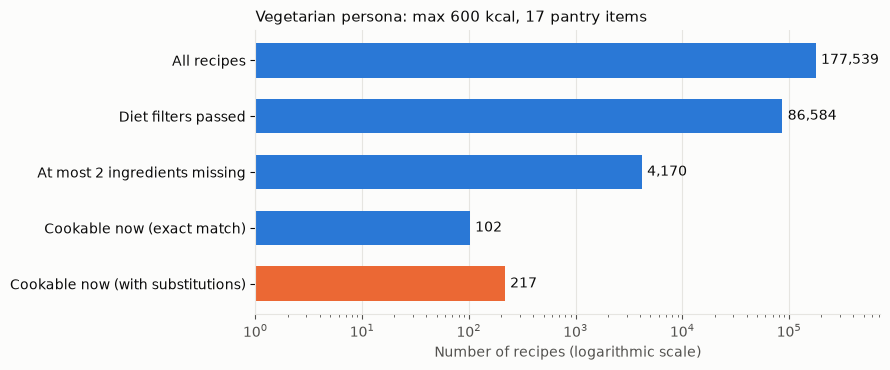

All recipes                                 177,539
Diet filters passed                          86,584
At most 2 ingredients missing                 4,170
Cookable now (exact match)                      102
Cookable now (with substitutions)               217


In [13]:
BLUE, ORANGE, INK, MUTED, GRID, SURFACE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": INK, "font.size": 10})

p = PERSONAS["Vegetarian, max 600 kcal"]
fun = rs.funnel(p["pantry"], **p["diet"])
labels, values = list(fun.keys()), list(fun.values())
fig, ax = plt.subplots(figsize=(9, 3.8))
colors = [BLUE] * 4 + [ORANGE]
ax.barh(range(len(values)), values, color=colors, height=0.62)
ax.set_xscale("log")
ax.set_yticks(range(len(values)), labels)
ax.invert_yaxis()
for i, v in enumerate(values):
    ax.text(v * 1.12, i, f"{v:,}", va="center", color=INK, fontsize=10)
ax.set_xlim(1, max(values) * 4)
ax.set_xlabel("Number of recipes (logarithmic scale)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.set_title("Vegetarian persona: max 600 kcal, 17 pantry items", loc="left", fontsize=11, color=INK)
plt.tight_layout()
plt.savefig("fig_recommender_funnel.png", dpi=200)
plt.show()
for k, v in fun.items():
    print(f"{k:42} {v:>8,}")

### 8c. Simulation: exact matching vs. matching with substitutions

**Design:** 400 random pantries, 100 each of 10, 15, 20 and 30 pantry items (staples always available).
Pantries are drawn from the non-staple pantry items, with a probability proportional to how often each item occurs in
recipes, so common items (onion, egg, butter) appear more often than rare ones (realistic pantries). Random seed = 42.

**Measures per pantry:**
- recipes cookable now with **exact matching** vs. **with substitutions**
- **dead end:** the user gets fewer than 5 recipes (the main frustration with pantry-based apps)
- **rescue share:** the share of the cookable recipes that are only shown because of a substitution

In [14]:
rng = np.random.default_rng(42)
item_freq = (pantry[~pantry["staple"]].groupby("pantry_item")["recipes"].sum())
items, prob = item_freq.index.to_numpy(), (item_freq / item_freq.sum()).to_numpy()
SIZES, N_PER_SIZE = [10, 15, 20, 30], 100

sim = []
for size in SIZES:
    for k in range(N_PER_SIZE):
        pantry_k = list(rng.choice(items, size=size, replace=False, p=prob))
        c = rs.cookable(pantry_k)
        sim.append({"pantry_size": size, "exact": int(c["exact"].sum()), "with_substitutions": int(c["with_subs"].sum()),
                    "near_1_missing": int((c["valid"] & (c["missing_exact"] <= 1)).sum()),
                    "pantry": ", ".join(pantry_k)})
sim = pd.DataFrame(sim)
sim["rescue_share"] = np.where(sim["with_substitutions"] > 0,
                               (sim["with_substitutions"] - sim["exact"]) / sim["with_substitutions"].clip(lower=1), 0)
sim.to_csv("simulation_results.csv", index=False, **CSV)

summary = sim.groupby("pantry_size").agg(
    median_exact=("exact", "median"), median_with_subs=("with_substitutions", "median"),
    dead_end_exact=("exact", lambda s: (s < 5).mean()),
    dead_end_with_subs=("with_substitutions", lambda s: (s < 5).mean()),
    rescue_share=("rescue_share", "mean"))
summary["gain"] = summary["median_with_subs"] / summary["median_exact"].clip(lower=1) - 1
display(summary.style.format({"median_exact": "{:.0f}", "median_with_subs": "{:.0f}", "dead_end_exact": "{:.0%}",
                              "dead_end_with_subs": "{:.0%}", "rescue_share": "{:.0%}", "gain": "+{:.0%}"}))

,median_exact,median_with_subs,dead_end_exact,dead_end_with_subs,rescue_share,gain
pantry_size,,,,,,
10,15,59,24%,2%,74%,+293%
15,46,164,2%,0%,72%,+260%
20,89,316,1%,0%,72%,+256%
30,296,1006,0%,0%,69%,+240%


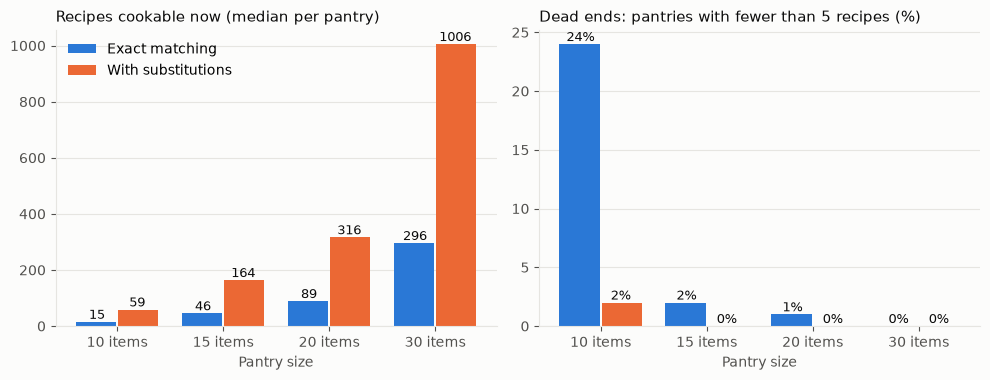

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
x = np.arange(len(SIZES))
w = 0.38
ax = axes[0]
ax.bar(x - w / 2 - 0.01, summary["median_exact"], w, color=BLUE, label="Exact matching")
ax.bar(x + w / 2 + 0.01, summary["median_with_subs"], w, color=ORANGE, label="With substitutions")
for i, (a, b) in enumerate(zip(summary["median_exact"], summary["median_with_subs"])):
    ax.text(i - w / 2, a, f"{a:.0f}", ha="center", va="bottom", fontsize=9, color=INK)
    ax.text(i + w / 2, b, f"{b:.0f}", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_title("Recipes cookable now (median per pantry)", loc="left", fontsize=11, color=INK)
ax.set_xticks(x, [f"{s} items" for s in SIZES])
ax.set_xlabel("Pantry size")

ax = axes[1]
ax.bar(x - w / 2 - 0.01, summary["dead_end_exact"] * 100, w, color=BLUE, label="Exact matching")
ax.bar(x + w / 2 + 0.01, summary["dead_end_with_subs"] * 100, w, color=ORANGE, label="With substitutions")
for i, (a, b) in enumerate(zip(summary["dead_end_exact"], summary["dead_end_with_subs"])):
    ax.text(i - w / 2, a * 100, f"{a:.0%}", ha="center", va="bottom", fontsize=9, color=INK)
    ax.text(i + w / 2, b * 100, f"{b:.0%}", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_title("Dead ends: pantries with fewer than 5 recipes (%)", loc="left", fontsize=11, color=INK)
ax.set_xticks(x, [f"{s} items" for s in SIZES])
ax.set_xlabel("Pantry size")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", colors=MUTED)
axes[0].legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.savefig("fig_recommender_simulation.png", dpi=200)
plt.show()

**How to read the simulation.** With exact matching, a small pantry (10 items) often leads to a dead end: about a quarter
of the pantries get fewer than 5 recipes. Substitutions remove almost all dead ends and multiply the number of cookable
recipes. The gain in the random pantries (medians between +240% and +290%) is **larger than for most personas** (see 8a), because
random pantries are less coherent than real kitchens (e.g. margarine but no butter), so more recipes depend on a swap.
The simulation therefore shows the upper range, and the personas show the realistic range. Both point the same way:
the substitution network matters most exactly where exact matching fails, i.e. with small pantries.

## 9. Flow diagram of the system (figure for 3.4.1)

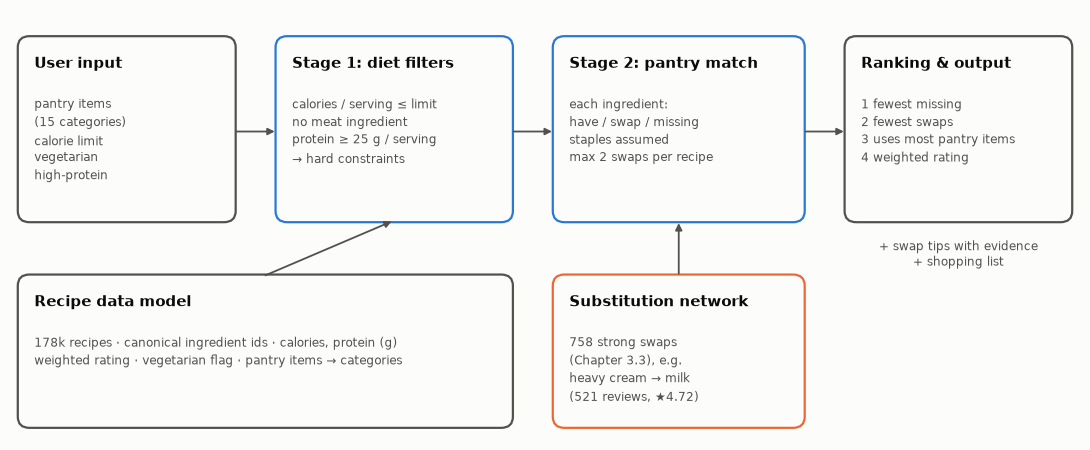

In [16]:
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.set_xlim(0, 11); ax.set_ylim(0, 4.6); ax.axis("off")

def box(x, y, w, h, title, body, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                facecolor=SURFACE, edgecolor=color, linewidth=1.6))
    ax.text(x + 0.15, y + h - 0.2, title, ha="left", va="top", fontsize=10.5, fontweight="bold", color=INK)
    ax.text(x + 0.15, y + h - 0.62, body, ha="left", va="top", fontsize=8.8, color=MUTED, linespacing=1.45)

def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.3))

box(0.1, 2.35, 2.2, 1.95, "User input", "pantry items\n(15 categories)\ncalorie limit\nvegetarian\nhigh-protein", MUTED)
box(2.75, 2.35, 2.4, 1.95, "Stage 1: diet filters", "calories / serving ≤ limit\nno meat ingredient\nprotein ≥ 25 g / serving\n→ hard constraints", BLUE)
ex = strong[(strong["a"] == "heavy cream") & (strong["b"] == "milk")].iloc[0]
box(5.6, 2.35, 2.55, 1.95, "Stage 2: pantry match", "each ingredient:\nhave / swap / missing\nstaples assumed\nmax 2 swaps per recipe", BLUE)
box(8.6, 2.35, 2.3, 1.95, "Ranking & output", "1 fewest missing\n2 fewest swaps\n3 uses most pantry items\n4 weighted rating", MUTED)
box(5.6, 0.15, 2.55, 1.6, "Substitution network", f"{len(strong):,} strong swaps\n(Chapter 3.3), e.g.\nheavy cream → milk\n({ex['support']} reviews, ★{ex['mean_rating']})", ORANGE)
box(0.1, 0.15, 5.05, 1.6, "Recipe data model", "178k recipes · canonical ingredient ids · calories, protein (g)\n"
    "weighted rating · vegetarian flag · pantry items → categories", MUTED)
arrow(2.3, 3.3, 2.75, 3.3); arrow(5.15, 3.3, 5.6, 3.3); arrow(8.15, 3.3, 8.6, 3.3)
arrow(6.875, 1.75, 6.875, 2.35)
arrow(2.6, 1.75, 3.95, 2.35)
ax.text(9.75, 2.15, "+ swap tips with evidence\n+ shopping list", ha="center", va="top", fontsize=8.8, color=MUTED)
plt.tight_layout()
plt.savefig("fig_recommender_flow.png", dpi=200)
plt.show()

## 10. Key numbers for the thesis

In [17]:
key = {
    "recipes in catalogue": len(rec),
    "pantry items": pantry["pantry_item"].nunique(),
    "pantry categories": pantry["category"].nunique(),
    "vegetarian by rule": f"{rec['vegetarian'].mean():.1%}",
    "vegetarian by tag": f"{rec['vegetarian_tag'].mean():.1%}",
    "tagged vegetarian but with meat": len(bad),
    "high-protein (>= 25 g)": f"{(rec['protein_g'] >= 25).mean():.1%}",
    "<= 600 kcal / serving": f"{(rec['calories'] <= 600).mean():.1%}",
    "substitution edges used (strong)": len(strong),
    "median gain from substitutions (all pantries)": f"+{(sim['with_substitutions'].median() / max(sim['exact'].median(), 1) - 1):.0%}",
    "mean rescue share": f"{sim['rescue_share'].mean():.0%}",
}
for k, v in key.items():
    print(f"{k:48} {v}")

recipes in catalogue                             177539
pantry items                                     307
pantry categories                                15
vegetarian by rule                               57.1%
vegetarian by tag                                15.4%
tagged vegetarian but with meat                  649
high-protein (>= 25 g)                           25.8%
<= 600 kcal / serving                            82.3%
substitution edges used (strong)                 758
median gain from substitutions (all pantries)    +298%
mean rescue share                                72%
